# San Francisco Public Salaries Analysis 

**Questions:** how is public-sector pay structured, how has it changed over the years, which job groups earn the most, and how unequal is pay?

**Dataset:** SF Salaries (public employee pay records, several years). Individual names are **not displayed**: the analysis looks at groups, not people.

**Tools:** Python, pandas, NumPy, Matplotlib, Seaborn, SciPy

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style='whitegrid')
pd.options.display.float_format = '{:,.0f}'.format

# 'Not Provided' means missing, so convert it to NaN while reading
df = pd.read_csv(r'Salaries.csv', na_values=['Not Provided', 'Not provided'])
pay_cols = ['BasePay', 'OvertimePay', 'OtherPay', 'Benefits', 'TotalPay', 'TotalPayBenefits']
df[pay_cols] = df[pay_cols].apply(pd.to_numeric, errors='coerce')
df.shape

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_18528\3351740080.py:11: DtypeWarning: Columns (12) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(r'Salaries.csv', na_values=['Not Provided', 'Not provided'])


(148654, 13)

## 1. Data quality

In [3]:
quality = pd.DataFrame({'missing': df.isnull().sum(), 'missing_%': df.isnull().mean() * 100})
print(quality[quality['missing'] > 0].to_string(float_format='{:,.1f}'.format))
print('\nDuplicate rows:', df.duplicated().sum())
print('Negative pay values:', (df[pay_cols] < 0).any(axis=1).sum())
print('Rows with total pay of 0 or less:', (df['TotalPay'] <= 0).sum())
print('\nMissing Benefits by year:'); print(df.groupby('Year')['Benefits'].apply(lambda s: s.isnull().mean() * 100).round(1))

              missing  missing_%
EmployeeName        6        0.0
JobTitle            4        0.0
BasePay           609        0.4
OvertimePay         4        0.0
OtherPay            4        0.0
Benefits        36163       24.3
Notes          148654      100.0
Status         110535       74.4

Duplicate rows: 0
Negative pay values: 21
Rows with total pay of 0 or less: 369

Missing Benefits by year:
Year
2011   100
2012     0
2013     0
2014     0
Name: Benefits, dtype: float64


**Decisions:**
- Missing pay is **kept as missing**, not replaced by 0, because filling with 0 would pull every average down.
- Years where `Benefits` is missing cannot be compared on `TotalPayBenefits`, so **trends use `TotalPay`**.
- Rows with zero or negative total pay are removed from pay statistics.

## 2. Clean the data

In [4]:
useless = [c for c in ['Id', 'Notes', 'Agency', 'Status'] if c in df.columns]
df = df.drop(columns=useless).drop_duplicates()
df['JobTitle'] = df['JobTitle'].str.upper().str.strip()
df = df[df['TotalPay'] > 0].copy()

# Group job titles into broad categories
patterns = [
    ('Police', 'POLICE|SERGEANT|SHERIFF|DEPUTY SHERIFF|OFFICER'),
    ('Fire', 'FIRE|FIREFIGHTER|BATTALION'),
    ('Health', 'NURSE|PHYSICIAN|MEDICAL|HEALTH|PSYCHIATR|PHARMAC|SURGEON'),
    ('Transit', 'TRANSIT|MUNI|MOTOR COACH|MECHANIC|OPERATOR'),
    ('Engineering & IT', 'ENGINEER|IS |PROGRAMMER|ANALYST|ARCHITECT'),
    ('Management', 'MANAGER|DIRECTOR|CHIEF|SUPERVISOR|ADMINISTRATOR'),
]
conds = [df['JobTitle'].str.contains(p, regex=True, na=False) for _, p in patterns]
df['category'] = np.select(conds, [n for n, _ in patterns], default='Other')
df['has_overtime'] = df['OvertimePay'] > 0
print('Clean records:', len(df))
print(df['category'].value_counts())

Clean records: 148285
category
Other               72690
Health              21544
Police              16462
Transit             14591
Engineering & IT    10516
Management           6612
Fire                 5870
Name: count, dtype: int64


## 3. How is pay distributed?

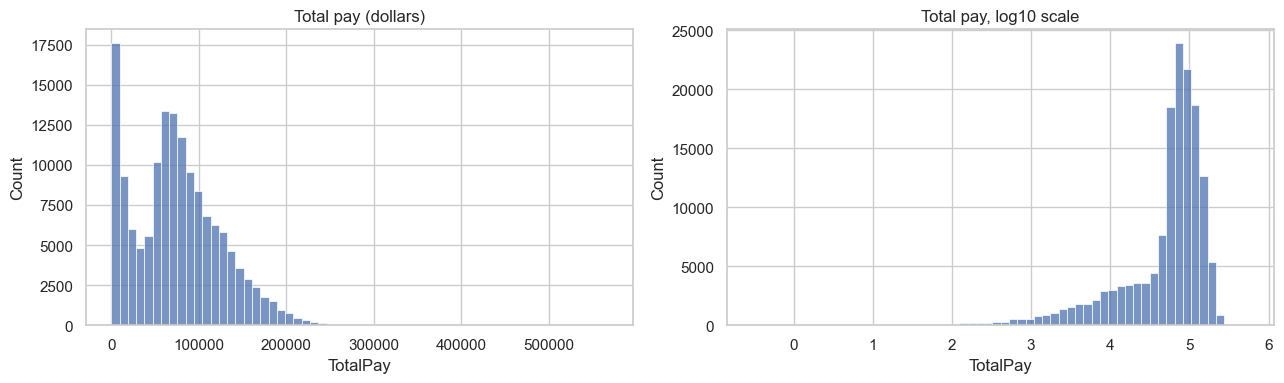

Mean: 74954 | Median: 71553
0     7,503
0    36,679
0    71,553
1   105,967
1   142,583
1   207,066
Name: TotalPay, dtype: float64


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df['TotalPay'], bins=60, ax=ax[0]).set_title('Total pay (dollars)')
sns.histplot(np.log10(df['TotalPay']), bins=60, ax=ax[1]).set_title('Total pay, log10 scale')
plt.tight_layout(); plt.show()
print('Mean:', round(df['TotalPay'].mean()), '| Median:', round(df['TotalPay'].median()))
print(df['TotalPay'].quantile([.1, .25, .5, .75, .9, .99]))

A mean above the median means a small group of very high earners pulls the average up, so **the median is the better measure of a typical employee**.

## 4. How has pay changed over the years?

      headcount   mean  median
Year                          
2011      36156 71,750  68,218
2012      36741 74,164  70,753
2013      37318 78,210  74,875
2014      38070 75,569  72,414


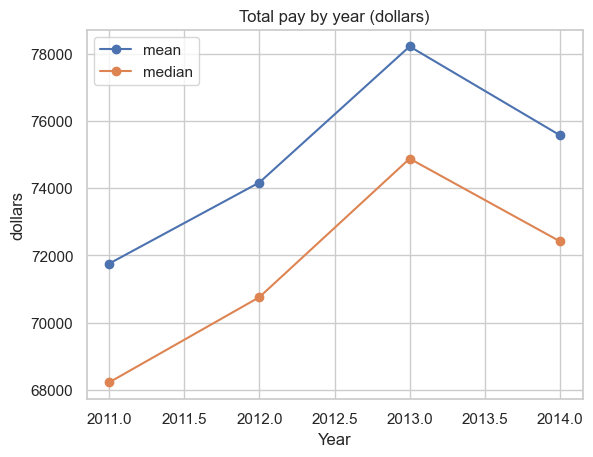

In [6]:
yearly = df.groupby('Year')['TotalPay'].agg(headcount='count', mean='mean', median='median')
print(yearly)
yearly[['mean', 'median']].plot(marker='o', title='Total pay by year (dollars)')
plt.ylabel('dollars'); plt.show()

## 5. What is pay made of?

      BasePay  OvertimePay  OtherPay
Year                                
2011       89            6         5
2012       88            7         5
2013       88            7         5
2014       88            7         5


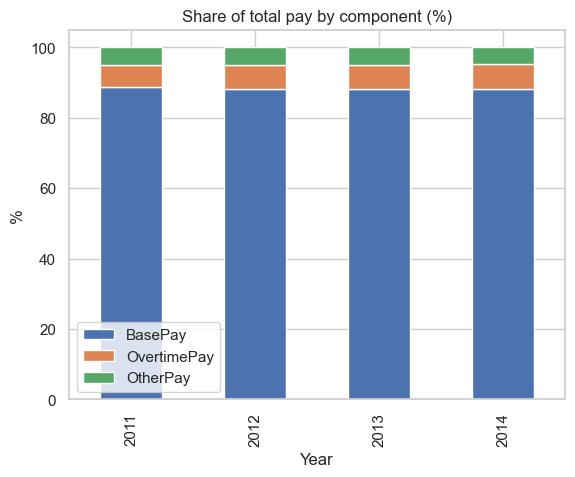


Share of employees with overtime (%):
Year
2011   48
2012   48
2013   48
2014   49
Name: has_overtime, dtype: float64


In [7]:
comp = df.groupby('Year')[['BasePay', 'OvertimePay', 'OtherPay']].sum()
comp_share = comp.div(comp.sum(axis=1), axis=0) * 100
print(comp_share.round(1))
comp_share.plot(kind='bar', stacked=True, title='Share of total pay by component (%)')
plt.ylabel('%'); plt.show()
print('\nShare of employees with overtime (%):')
print((df.groupby('Year')['has_overtime'].mean() * 100).round(1))

## 6. Which jobs earn the most?

                  headcount  median    mean
category                                   
Other                 72690  57,566  57,027
Health                21544  64,426  71,276
Transit               14591  76,177  73,219
Engineering & IT      10516  93,923  91,018
Management             6612 112,135 108,866
Police                16462 115,598 109,141
Fire                   5870 153,763 151,918


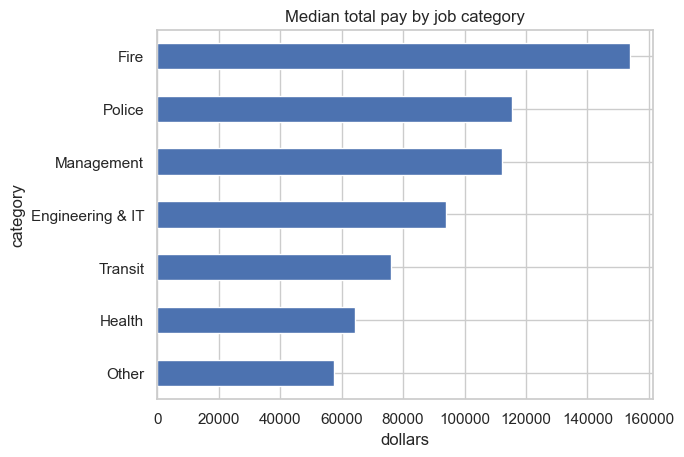

In [8]:
cat = df.groupby('category')['TotalPay'].agg(headcount='count', median='median', mean='mean').sort_values('median')
print(cat)
cat['median'].plot(kind='barh', title='Median total pay by job category')
plt.xlabel('dollars'); plt.show()

In [9]:
titles = df.groupby('JobTitle')['TotalPay'].agg(headcount='count', median='median')
common = titles[titles['headcount'] >= 30]
print('Top 10 best-paid job titles (at least 30 employees):')
print(common.sort_values('median', ascending=False).head(10))
print('\n10 most common job titles:')
print(titles.sort_values('headcount', ascending=False).head(10))

Top 10 best-paid job titles (at least 30 employees):
                                    headcount  median
JobTitle                                             
BATTALION CHIEF, FIRE SUPPRESS             65 256,742
BATTLION CHIEF, FIRE SUPPRESSI             36 233,606
BATTALION CHIEF, (FIRE DEPARTMENT)         45 221,049
CAPTAIN 3                                 101 212,534
DEP DIR V                                  50 202,562
SUPERVISING PHYSICIAN SPEC                 52 202,430
MANAGER VIII                               97 201,953
ASSISTANT CHIEF ATTORNEY 1                 71 200,792
CAPTAIN III (POLICE DEPARTMENT)            37 198,884
CAPTAIN, FIRE SUPPRESSION                 282 193,926

10 most common job titles:
                              headcount  median
JobTitle                                       
TRANSIT OPERATOR                   9381  72,099
SPECIAL NURSE                      5788  19,737
REGISTERED NURSE                   4953 121,551
CUSTODIAN                      

## 7. Overtime

Employees with overtime above 50% of base pay: 3397

Overtime as share of total pay, by category (%):
category
Engineering & IT    1
Management          2
Health              3
Other               4
Police             10
Transit            17
Fire               17
dtype: float64


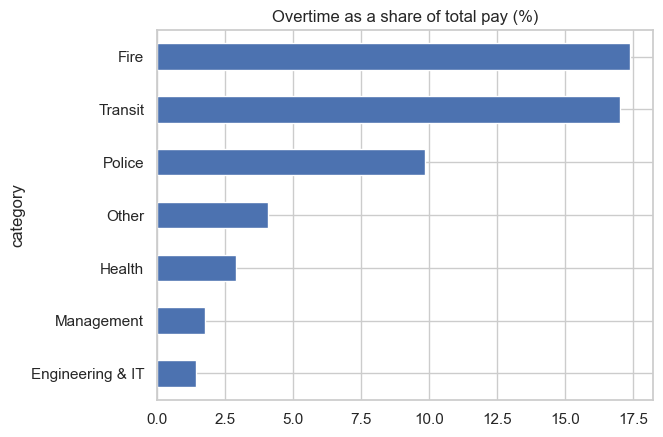

In [10]:
ot = df[df['has_overtime']].copy()
ot['overtime_vs_base_%'] = ot['OvertimePay'] / ot['BasePay'] * 100
print('Employees with overtime above 50% of base pay:', (ot['overtime_vs_base_%'] > 50).sum())
print('\nOvertime as share of total pay, by category (%):')
share = (df.groupby('category')['OvertimePay'].sum() / df.groupby('category')['TotalPay'].sum() * 100).sort_values()
print(share.round(1))
share.plot(kind='barh', title='Overtime as a share of total pay (%)'); plt.show()

## 8. How unequal is pay?

In [11]:
pay = np.sort(df['TotalPay'].values)
top1 = pay[int(len(pay) * 0.99):].sum() / pay.sum() * 100
top10 = pay[int(len(pay) * 0.90):].sum() / pay.sum() * 100
gini = (2 * np.sum((np.arange(1, len(pay) + 1)) * pay) / (len(pay) * pay.sum())) - (len(pay) + 1) / len(pay)
print(f'Top 1% of employees receive {top1:.1f}% of all pay')
print(f'Top 10% of employees receive {top10:.1f}% of all pay')
print(f'Gini coefficient: {gini:.2f}  (0 = equal, 1 = very unequal)')
print(f'90th percentile pay is {df.TotalPay.quantile(.9) / df.TotalPay.quantile(.1):.1f}x the 10th percentile')

Top 1% of employees receive 3.1% of all pay
Top 10% of employees receive 23.0% of all pay
Gini coefficient: 0.38  (0 = equal, 1 = very unequal)
90th percentile pay is 19.0x the 10th percentile


## 9. Relationships and statistical checks

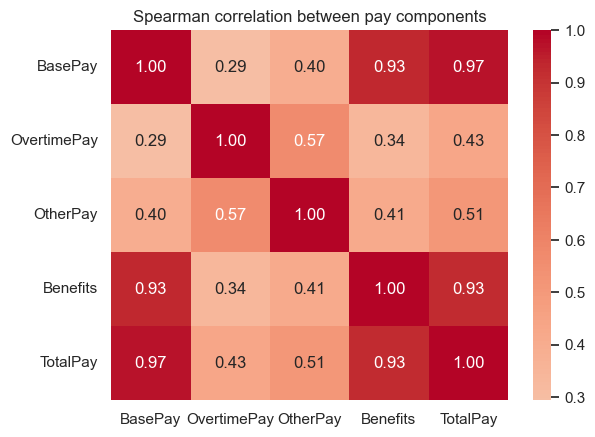

Median total pay 2011: 68,218 | 2014: 72,414 | p-value = 0.0000


In [12]:
num = df[['BasePay', 'OvertimePay', 'OtherPay', 'Benefits', 'TotalPay']].dropna()
sns.heatmap(num.corr(method='spearman'), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Spearman correlation between pay components'); plt.show()

years = sorted(df['Year'].unique())
first = df.loc[df['Year'] == years[0], 'TotalPay']; last = df.loc[df['Year'] == years[-1], 'TotalPay']
u, p = stats.mannwhitneyu(first, last)
print(f'Median total pay {years[0]}: {first.median():,.0f} | {years[-1]}: {last.median():,.0f} | p-value = {p:.4f}')

Spearman correlation and the Mann-Whitney test are used instead of the usual correlation and t-test because pay is strongly skewed.

## Key findings

- **Data quality:** 148,654 records, 24.3% missing benefits, 369 rows removed (total pay of 0 or less), leaving 148,285 clean records
- **Typical pay:** the median total pay is [see snippet], while the mean is [see snippet], because a small group of very high earners pulls the mean up (the mean is above the median in every year)
- **Over time:** median pay moved from 68,218 in 2011 to 72,414 in 2014 (+6.2%), a statistically significant change (p < 0.001)
- **Jobs:** the highest-paid category is ... and the lowest is ...; at title level, fire battalion chiefs earn the most (median about 220,000-257,000), while the most common titles include many part-time or seasonal roles (e.g. Recreation Leader, median 5,399)
- **Overtime:** Fire and Transit rely most on overtime (17% of their pay each), followed by Police (10%)
- **Inequality:** the top 1% receive 3.1% of all pay (Gini 0.38), and the top 10% receive 23.0%

## Limitations
- Pay records show earnings, not hours worked, seniority, or whether an employee worked part of the year, so low pay may reflect part-time or partial-year work.
- Job categories are built from keywords in job titles, and about 49% of records fall into "Other", so category comparisons cover only part of the workforce.
- Benefits are missing for all of 2011, so comparisons across years use total pay excluding benefits.
- There is no employee ID, so the same person may appear in several years.
- 369 records with total pay of 0 or less were removed; `Notes` and `Status` were too incomplete to use.